<a href="https://colab.research.google.com/github/asegura4488/EDCO_IntroCienciaDatos/blob/main/Semana5/Red_Neuronal_Keras_Auto_MPG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ¿Puede una red neuronal mejorar la regresión lineal? — Auto MPG
### Notebook de clase: Keras · Dropout · EarlyStopping · métricas de entrenamiento y generalización

**Pregunta:** dado un automóvil, ¿podemos predecir su eficiencia `mpg` con mayor precisión que mediante la regresión lineal del EDA?

Trabajaremos con **el mismo archivo** (`Auto_MPG_UCI(3).csv`), **el mismo conjunto de prueba** del notebook EDA (`test_size=0.20`, `random_state=42`) y las mismas variables explicativas. No utilizaremos `car_name` como predictor.

**Secuencia:**

1. Cargar datos, reservar prueba y reproducir la mejor regresión lineal del EDA.
2. Construir un conjunto de ajuste y otro de validación, sin mezclar sus funciones.
3. Imputar los faltantes, estandarizar las columnas numéricas y codificar `origin`.
4. Entrenar redes con tasas de **Dropout 0 %, 15 % y 30 %**, con **EarlyStopping** y **ReduceLROnPlateau**.
5. Examinar `loss`, **MAE** y **RMSE** en entrenamiento y validación por época.
6. Elegir la tasa de Dropout solo con validación, reentrenar con todo el conjunto de entrenamiento y **evaluar una sola vez en prueba**.
7. Comparar los dos modelos mediante MAE, RMSE, R² y gráficos de residuos.

> El conjunto de datos es pequeño (398 automóviles), así que una red neuronal **no tiene garantizado** superar a una regresión lineal. La conclusión dependerá de los resultados medidos en prueba, no del error de entrenamiento.

## 0. Bibliotecas y reproducibilidad

Para **Google Colab** normalmente basta ejecutar las celdas. En un Python local, instala antes:

```bash
pip install numpy pandas matplotlib seaborn scikit-learn tensorflow keras joblib
```

El cuaderno usa **Keras 3**. Si TensorFlow no está disponible, pero tienes PyTorch instalado, selecciona automáticamente ese motor (las capas y callbacks de Keras son los mismos). No es necesario instalar *los dos* motores.

In [ ]:
import os
import importlib.util

# Elegir el motor antes de importar Keras: TensorFlow si existe;
# si no, PyTorch como alternativa para ejecutar Keras 3.
if importlib.util.find_spec("tensorflow") is not None:
    os.environ["KERAS_BACKEND"] = "tensorflow"
elif importlib.util.find_spec("torch") is not None:
    os.environ["KERAS_BACKEND"] = "torch"
else:
    raise ImportError("Instala TensorFlow (pip install tensorflow) para utilizar Keras.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from joblib import dump

import keras
from keras import layers, regularizers, callbacks

# Limitar hilos evita la ralentización por sobresuscripción en CPU con PyTorch.
if keras.backend.backend() == "torch":
    import torch
    torch.set_num_threads(2)

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
print("Keras:", keras.__version__, "| backend:", keras.backend.backend())

Keras: 3.13.2 | backend: tensorflow


In [ ]:
import os
from google.colab import drive
from google.colab import files
drive.mount('/content/drive', force_remount=True)
# Necesito ir a la carpeta del curso
os.chdir('/content/drive/MyDrive/EDCO_IntroCienciaDatos/Semana5/Datos')

Mounted at /content/drive


## 1. Carga de los 398 automóviles

El archivo CSV debe estar en el mismo directorio del notebook. En Colab, si no está, se abre la opción de **subirlo directamente**: no necesitas montar Drive. Los nombres alternativos permiten seguir usando tus versiones anteriores del CSV.

In [ ]:
archivos = [
    Path("Auto_MPG_UCI(3).csv"), Path("Auto_MPG_UCI(2).csv"),
    Path("Auto_MPG_UCI.csv"), Path("/mnt/data/Auto_MPG_UCI(3).csv")
]
ruta = next((p for p in archivos if p.exists()), None)
if ruta is None:
    try:
        from google.colab import files
        print("Sube tu archivo Auto_MPG_UCI(3).csv:")
        subidos = files.upload()
        nombre = next((n for n in subidos if n.lower().endswith(".csv")), None)
        if nombre is None:
            raise FileNotFoundError("No se cargó ningún archivo CSV.")
        ruta = Path(nombre)
    except ImportError as exc:
        raise FileNotFoundError("Coloca Auto_MPG_UCI(3).csv junto al notebook.") from exc

datos = pd.read_csv(ruta)
columnas_originales = [
    "mpg", "cylinders", "displacement", "horsepower", "weight",
    "acceleration", "model_year", "origin"
]
for c in columnas_originales:
    datos[c] = pd.to_numeric(datos[c], errors="coerce")

print("Fuente:", ruta, "| Forma:", datos.shape)
display(datos.head())
print("Faltantes por variable:")
display(datos.isna().sum().to_frame("n_faltantes").T)

Fuente: Auto_MPG_UCI.csv | Forma: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


Faltantes por variable:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
n_faltantes,0,0,0,6,0,0,0,0,0


## 2. Diseño del experimento: entrenamiento, validación y prueba

- **Entrenamiento externo (80 %):** sirve para elegir y ajustar modelos.
- **Prueba (20 %):** queda intacta hasta la comparación final.
- **Entrenamiento interno y validación:** dentro del entrenamiento externo, el 20 % se usa para detectar sobreajuste y ajustar Dropout y la época de parada.

**Nota sobre comparabilidad:** la regresión del EDA usa validación cruzada para seleccionar variables y luego se ajusta sobre **todo el 80 % externo**. Para la red, la validación interna determina los hiperparámetros; después **volvemos a entrenar desde cero sobre todo ese mismo 80 % externo**, durante el número de épocas elegido. Así ambos modelos aprovechan finalmente los mismos registros y se evalúan sobre el mismo test.

In [ ]:
# EXACTAMENTE la misma división de prueba del EDA previo.
entrenamiento, prueba = train_test_split(datos, test_size=0.20, random_state=SEMILLA)

# División usada ÚNICAMENTE para seleccionar parámetros de la red.
ajuste, validacion = train_test_split(entrenamiento, test_size=0.20, random_state=123)

y_ajuste = ajuste["mpg"].to_numpy(dtype="float32")
y_val = validacion["mpg"].to_numpy(dtype="float32")
y_entrenamiento = entrenamiento["mpg"].to_numpy(dtype="float32")
y_prueba = prueba["mpg"].to_numpy(dtype="float32")

print(f"Total: {len(datos)}; entrenamiento externo: {len(entrenamiento)}; prueba: {len(prueba)}")
print(f"De entrenamiento externo: ajuste NN = {len(ajuste)}, validación NN = {len(validacion)}")
assert set(ajuste.index).isdisjoint(validacion.index)
assert set(entrenamiento.index).isdisjoint(prueba.index)

Total: 398; entrenamiento externo: 318; prueba: 80
De entrenamiento externo: ajuste NN = 254, validación NN = 64


## 3. Recuperar la regresión lineal del EDA

Repetimos las **cinco configuraciones** del cuaderno anterior; seleccionamos la de menor MAE de validación cruzada **solo sobre los 318 automóviles del entrenamiento externo**. La comparación posterior se realizará también contra la regresión lineal que utiliza **todas las variables de entrada de la red**, para aislar el efecto de la no linealidad.

La imputación de `horsepower` ocurre dentro de cada fold y la categoría nominal `origin` se transforma mediante variables indicadoras (*one-hot*).

In [ ]:
configuraciones = {
    "A. Solo peso": ["weight"],
    "B. Peso + año": ["weight", "model_year"],
    "C. Peso + año + potencia": ["weight", "model_year", "horsepower"],
    "D. Todas numéricas": ["weight", "model_year", "horsepower", "displacement", "acceleration", "cylinders"],
    "E. Numéricas + origen": ["weight", "model_year", "horsepower", "displacement", "acceleration", "cylinders", "origin"]
}

def crear_lineal(columnas):
    num = [c for c in columnas if c != "origin"]
    cat = [c for c in columnas if c == "origin"]
    pasos = [("num", SimpleImputer(strategy="median"), num)]
    if cat:
        pasos.append(("cat", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
        ]), cat))
    return Pipeline([
        ("preproceso", ColumnTransformer(pasos)),
        ("modelo", LinearRegression())
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, columnas in configuraciones.items():
    validacion_cv = cross_validate(
        crear_lineal(columnas), entrenamiento[columnas], entrenamiento["mpg"],
        cv=cv, scoring={"mae": "neg_mean_absolute_error", "r2": "r2"}
    )
    filas.append({
        "Modelo": nombre,
        "MAE_CV_mpg": -validacion_cv["test_mae"].mean(),
        "R2_CV": validacion_cv["test_r2"].mean()
    })
tabla_cv = pd.DataFrame(filas).sort_values("MAE_CV_mpg")
display(tabla_cv.round(3))

mejor_lineal_nombre = tabla_cv.iloc[0]["Modelo"]
columnas_mejor_lineal = configuraciones[mejor_lineal_nombre]
lineal_eda = crear_lineal(columnas_mejor_lineal)
lineal_eda.fit(entrenamiento[columnas_mejor_lineal], entrenamiento["mpg"])
print("Selección CV de la regresión lineal:", mejor_lineal_nombre)

,Modelo,MAE_CV_mpg,R2_CV
4,E. Numéricas + origen,2.683,0.803
1,B. Peso + año,2.720,0.796
2,C. Peso + año + potencia,2.729,0.794
3,D. Todas numéricas,2.770,0.789
0,A. Solo peso,3.412,0.669


Selección CV de la regresión lineal: E. Numéricas + origen


## 4. Las entradas de la red: escalado + variables categóricas

En una red neuronal, las magnitudes tan diferentes (`weight` ~ miles, `model_year` ~ decenas) hacen difícil optimizar los pesos. Por eso transformamos cada columna numérica con

\[
z_j=\frac{x_j-\mu_j}{\sigma_j}.
\]

- Los faltantes de `horsepower` se reemplazan por la mediana **del conjunto de ajuste**.
- `origin` se representa como categorías independientes mediante *one-hot encoding*.
- **Nunca** ajustamos el imputador ni el escalador con validación o prueba.
- `car_name` se descarta: es texto nominal y no se ha diseñado una representación útil para él.

Usamos las seis variables numéricas + `origin` en todas las redes.

In [ ]:
variables_num = ["weight", "model_year", "horsepower", "displacement", "acceleration", "cylinders"]
variables_cat = ["origin"]
variables_red = variables_num + variables_cat

def crear_preprocesador():
    """Regresa nueva instancia; fit siempre solo con datos autorizados."""
    return ColumnTransformer([
        ("numericas", Pipeline([
            ("imputador", SimpleImputer(strategy="median")),
            ("escala", StandardScaler())
        ]), variables_num),
        ("origen", Pipeline([
            ("imputador", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), variables_cat)
    ], sparse_threshold=0)

pre_ajuste = crear_preprocesador()
X_ajuste = np.asarray(pre_ajuste.fit_transform(ajuste[variables_red]), dtype="float32")
X_val = np.asarray(pre_ajuste.transform(validacion[variables_red]), dtype="float32")
print("Forma para la red:", X_ajuste.shape, "; validación:", X_val.shape)
print("Columnas después del preprocesamiento:")
print(pre_ajuste.get_feature_names_out())

Forma para la red: (254, 9) ; validación: (64, 9)
Columnas después del preprocesamiento:
['numericas__weight' 'numericas__model_year' 'numericas__horsepower'
 'numericas__displacement' 'numericas__acceleration'
 'numericas__cylinders' 'origen__origin_1' 'origen__origin_2'
 'origen__origin_3']


## 5. Arquitectura de la red neuronal de regresión

\[
\boxed{\text{Entradas estandarizadas}} \longrightarrow
\operatorname{Dense}(32,\mathrm{ReLU}) \longrightarrow
\operatorname{Dropout}(p) \longrightarrow
\operatorname{Dense}(16,\mathrm{ReLU}) \longrightarrow
\operatorname{Dropout}(p) \longrightarrow
\operatorname{Dense}(1)
\]

La salida no tiene función de activación porque `mpg` es una cantidad continua. La red no tiene como objetivo clasificar automóviles; **no tiene sentido reportar `accuracy`**.

La función de pérdida es el **error cuadrático medio (MSE)** más un término de regularización L2. Para interpretar el rendimiento registramos además:

\[
\mathrm{MAE}=\frac{1}{n}\sum_i |y_i-\hat y_i|,
\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i(y_i-\hat y_i)^2}.
\]

El **MAE** y el **RMSE** se calculan en unidades de `mpg`; el `loss` puede ser un poco mayor que el MSE debido a la penalización L2.

**Dropout:** durante el entrenamiento desactiva aleatoriamente una fracción `p` de las activaciones; durante predicción no las elimina. Ayuda a reducir sobreajuste pero no garantiza mejores predicciones.

In [ ]:
def crear_red(n_entradas, tasa_dropout=0.20):
    modelo = keras.Sequential([
        keras.Input(shape=(n_entradas,)),
        layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(tasa_dropout),
        layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(tasa_dropout),
        layers.Dense(1)  # salida lineal: una predicción de mpg
    ])
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.003),
        loss="mse",
        metrics=[
            keras.metrics.MeanAbsoluteError(name="mae"),
            keras.metrics.RootMeanSquaredError(name="rmse")
        ]
    )
    return modelo

red_de_muestra = crear_red(X_ajuste.shape[1], tasa_dropout=0.15)
red_de_muestra.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_39 (Dense)                │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865 (3.38 KB)

 Trainable params: 865 (3.38 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenamiento con *callbacks*: EarlyStopping y ReduceLROnPlateau

**EarlyStopping** vigila el `val_mae`, y si deja de mejorar durante 30 épocas, detiene el entrenamiento. `restore_best_weights=True` recupera los pesos de la mejor época de validación, **no** los pesos de la última época. **ReduceLROnPlateau** reduce la tasa de aprendizaje a la mitad cuando no hay avance durante 12 épocas.

Para estudiar Dropout, entrenamos modelos con **0 %, 15 % y 30 %**. No usaremos datos de prueba para elegir la tasa. Con 398 filas, es posible que una tasa de Dropout alta haga que el modelo *subajuste* los datos.

> **¿Por qué separar una validación interna?** Porque si observáramos las curvas en test para decidir `p`, perderíamos una estimación imparcial de generalización.

In [ ]:
TASAS_DROPOUT = [0.00, 0.15, 0.30]
EPOCAS_MAX = 250
BATCH_SIZE = 16
experimentos = {}

for i, tasa in enumerate(TASAS_DROPOUT):
    keras.utils.set_random_seed(SEMILLA + i)
    red = crear_red(X_ajuste.shape[1], tasa_dropout=tasa)

    detener = callbacks.EarlyStopping(
        monitor="val_mae", mode="min", patience=30,
        restore_best_weights=True, verbose=0
    )
    reducir_tasa = callbacks.ReduceLROnPlateau(
        monitor="val_mae", mode="min", factor=0.5,
        patience=12, min_lr=1e-5, verbose=0
    )

    historial = red.fit(
        X_ajuste, y_ajuste,
        validation_data=(X_val, y_val),
        epochs=EPOCAS_MAX,
        batch_size=BATCH_SIZE,
        callbacks=[detener, reducir_tasa],
        verbose=0
    )
    # La red tiene restaurados los pesos de la época de menor val_mae.
    metricas_val = red.evaluate(X_val, y_val, verbose=0, return_dict=True)
    mejor_epoca = int(np.argmin(historial.history["val_mae"]) + 1)
    experimentos[tasa] = {
        "modelo": red, "historial": historial.history,
        "mejor_epoca": mejor_epoca,
        "epocas_entrenadas": len(historial.history["loss"]),
        "val_mae": float(metricas_val["mae"]),
        "val_rmse": float(metricas_val["rmse"])
    }
    print(
        f"Dropout={tasa:.0%}  "
        f"épocas: {experimentos[tasa]['epocas_entrenadas']:3d}  "
        f"mejor época: {mejor_epoca:3d}  "
        f"MAE validación: {metricas_val['mae']:.3f} mpg  "
        f"RMSE validación: {metricas_val['rmse']:.3f} mpg"
    )

Dropout=0%  épocas: 250  mejor época: 250  MAE validación: 2.256 mpg  RMSE validación: 3.072 mpg
Dropout=15%  épocas:  69  mejor época:  39  MAE validación: 2.261 mpg  RMSE validación: 3.101 mpg
Dropout=30%  épocas:  69  mejor época:  39  MAE validación: 2.302 mpg  RMSE validación: 3.155 mpg


### 6.1 ¿Qué tasa de Dropout generaliza mejor en validación?

El modelo `p=0` sirve como control para ver si regularizar ayuda. Como el objetivo de esta clase es estudiar una red **con Dropout**, seleccionaremos la mejor tasa **positiva** (15 % o 30 %) según el **MAE de validación**. El caso 0 % se conserva como control para discutir si Dropout ayuda o perjudica. Esto no significa que 0 % sea inferior: podría obtener mejores métricas.

,Dropout,épocas ejecutadas,mejor época,MAE_validación,RMSE_validación
0,0.00,250,250,2.256,3.072
1,0.15,69,39,2.261,3.101
2,0.30,69,39,2.302,3.155


Elegida entre redes CON Dropout: p=15%; mejor época: 39
Control sin Dropout: MAE validación 2.256 mpg


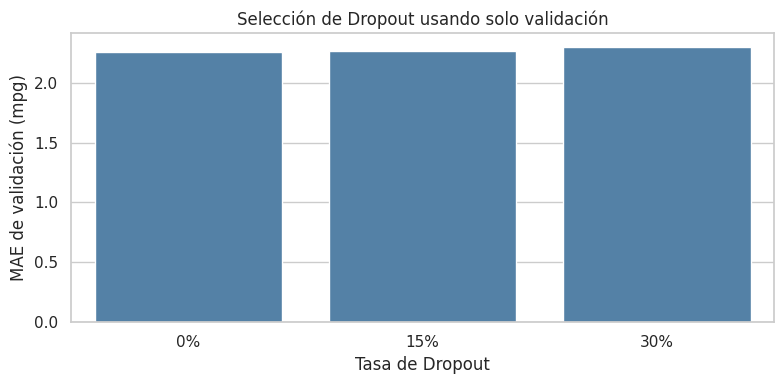

In [ ]:
tabla_dropout = pd.DataFrame([
    {
        "Dropout": tasa,
        "épocas ejecutadas": r["epocas_entrenadas"],
        "mejor época": r["mejor_epoca"],
        "MAE_validación": r["val_mae"],
        "RMSE_validación": r["val_rmse"]
    }
    for tasa, r in experimentos.items()
]).sort_values("MAE_validación").reset_index(drop=True)
display(tabla_dropout.round(3))

mejor_tasa = float(tabla_dropout.loc[tabla_dropout["Dropout"] > 0, "Dropout"].iloc[0])
mejor_epoca = int(experimentos[mejor_tasa]["mejor_epoca"])
print(f"Elegida entre redes CON Dropout: p={mejor_tasa:.0%}; mejor época: {mejor_epoca}")
print("Control sin Dropout: MAE validación", round(experimentos[0.0]["val_mae"], 3), "mpg")

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=tabla_dropout, x="Dropout", y="MAE_validación", ax=ax, color="steelblue")
ax.set(title="Selección de Dropout usando solo validación", xlabel="Tasa de Dropout", ylabel="MAE de validación (mpg)")
ax.set_xticks(range(len(tabla_dropout)), labels=[f"{p:.0%}" for p in tabla_dropout["Dropout"]])
plt.tight_layout()
plt.show()

## 7. Curvas de aprendizaje: ¿hubo sobreajuste?

Estas son las curvas del **entrenamiento interno** usado para seleccionar Dropout y la mejor época (todavía no hemos visto test). Debes mirar:

- `loss` frente a `val_loss`: desempeño de la función objetivo (incluye regularización L2).
- `mae` frente a `val_mae`: error absoluto medio por época, en `mpg`.
- `rmse` frente a `val_rmse`: penaliza más los errores grandes, en `mpg`.

**Atención:** cuando usamos Dropout, a veces el entrenamiento registra peor error que la validación, porque Dropout está activo durante el entrenamiento y desactivado durante la evaluación. Esa diferencia, por sí sola, no es una señal de problema.

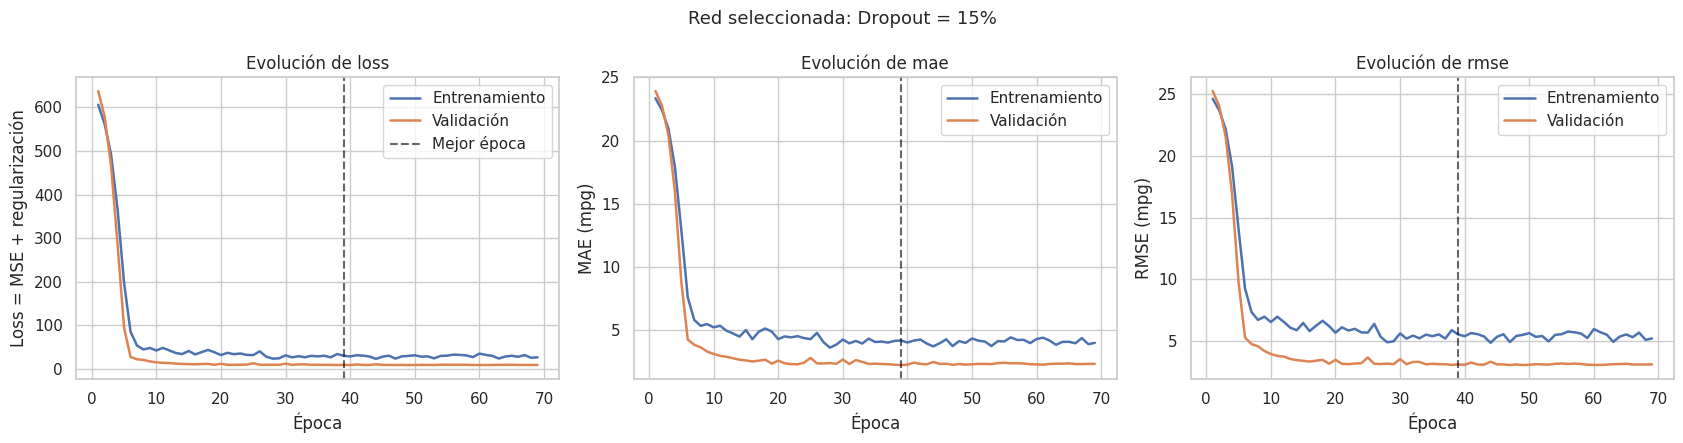

,loss,val_loss,mae,val_mae,rmse,val_rmse
epoca,,,,,,
60,35.600,9.417,4.319,2.313,5.966,3.068
61,32.635,9.352,4.426,2.290,5.712,3.057
62,30.363,9.524,4.196,2.344,5.510,3.085
63,24.281,9.747,3.863,2.371,4.927,3.121
64,28.722,9.812,4.095,2.374,5.359,3.131
65,30.584,9.945,4.100,2.394,5.530,3.153
66,28.186,9.605,3.986,2.342,5.308,3.098
67,32.246,9.570,4.392,2.337,5.678,3.092
68,25.937,9.625,3.914,2.355,5.092,3.101


In [ ]:
h = experimentos[mejor_tasa]["historial"]
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metrica, etiqueta in zip(
    ejes, ["loss", "mae", "rmse"],
    ["Loss = MSE + regularización", "MAE (mpg)", "RMSE (mpg)"]
):
    epocas = np.arange(1, len(h[metrica]) + 1)
    ax.plot(epocas, h[metrica], label="Entrenamiento", lw=1.8)
    ax.plot(epocas, h["val_" + metrica], label="Validación", lw=1.8)
    ax.axvline(mejor_epoca, ls="--", color="black", alpha=0.6, label="Mejor época" if metrica == "loss" else None)
    ax.set(xlabel="Época", ylabel=etiqueta, title=f"Evolución de {metrica}")
    ax.legend()
fig.suptitle(f"Red seleccionada: Dropout = {mejor_tasa:.0%}", fontsize=13)
plt.tight_layout()
plt.show()

# Mirar las últimas épocas para entender si el error dejó de reducirse.
df_historial = pd.DataFrame(h)
df_historial.index = df_historial.index + 1
df_historial.index.name = "epoca"
display(df_historial[["loss", "val_loss", "mae", "val_mae", "rmse", "val_rmse"]].tail(10).round(3))

### 7.1 Comparación de las tres tasas de Dropout a lo largo del aprendizaje

Una red sin Dropout puede ajustar muy bien el conjunto de entrenamiento, pero empeorar en validación. La decisión se toma por el **desempeño fuera de las muestras usadas para actualizar los pesos**.

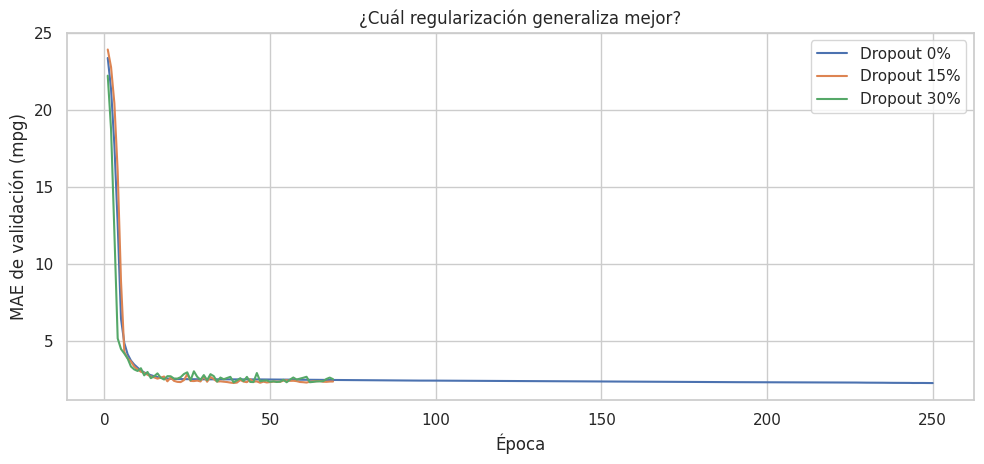

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for tasa, reg in experimentos.items():
    vals = reg["historial"]["val_mae"]
    ax.plot(np.arange(1, len(vals) + 1), vals, label=f"Dropout {tasa:.0%}")
ax.set(xlabel="Época", ylabel="MAE de validación (mpg)", title="¿Cuál regularización generaliza mejor?")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Reentrenamiento final de la red (sin mirar prueba)

Los hiperparámetros seleccionados mediante validación son:

- Tasa de Dropout: `mejor_tasa`.
- Número de épocas: `mejor_epoca` (mínimo MAE en validación).

Ahora volvemos a iniciar los pesos de una **nueva red** y la ajustamos usando los **318 automóviles de entrenamiento externo**. Ajustamos también de nuevo el preprocesamiento únicamente sobre esos automóviles. No se aplica EarlyStopping en esta fase, porque la cantidad de épocas **ya fue determinada por la validación anterior**; usar la validación otra vez para parar convertiría ese subconjunto en datos no entrenados.

Esta fase hace que regresión lineal y red aprovechen el mismo entrenamiento externo antes de la evaluación final.

In [ ]:
pre_final = crear_preprocesador()
X_entrenamiento = np.asarray(pre_final.fit_transform(entrenamiento[variables_red]), dtype="float32")
X_prueba = np.asarray(pre_final.transform(prueba[variables_red]), dtype="float32")

keras.utils.set_random_seed(SEMILLA + 100)
red_final = crear_red(X_entrenamiento.shape[1], tasa_dropout=mejor_tasa)
historial_final = red_final.fit(
    X_entrenamiento, y_entrenamiento,
    epochs=mejor_epoca, batch_size=BATCH_SIZE, verbose=0
)

# Otra regresión lineal con EXACTAMENTE los predictores originales de la red.
lineal_mismas_variables = crear_lineal(variables_red)
lineal_mismas_variables.fit(entrenamiento[variables_red], entrenamiento["mpg"])

# Métricas de entrenamiento final. No se usan para selección.
print("Métricas de la red sobre su entrenamiento final (pueden ser optimistas):")
print(red_final.evaluate(X_entrenamiento, y_entrenamiento, verbose=0, return_dict=True))

Métricas de la red sobre su entrenamiento final (pueden ser optimistas):
{'loss': 8.270234107971191, 'mae': 2.0750110149383545, 'rmse': 2.874767303466797}


## 9. EVALUACIÓN FINAL en los 80 automóviles reservados

**Esta es la primera vez que calculamos predicciones con el conjunto de prueba.** La comparación con la regresión lineal del EDA es válida porque ambas usan la partición `random_state=42` y ninguna empleó prueba para elegir hiperparámetros.

Interpretación: menor **MAE/RMSE** implica menor error de predicción; mayor **R²** implica mejor ajuste fuera de muestra respecto al predictor constante basado en la media del test. R² puede ser negativo.

,MAE (mpg),RMSE (mpg),R²
Modelo,,,
Regresión lineal (mejor CV del EDA),2.288,2.888,0.845
Regresión lineal (mismas entradas RN),2.288,2.888,0.845
Red Keras (Dropout 15%),1.888,2.321,0.900


La red MEJORÓ el MAE frente al EDA en 17.5 % en prueba.


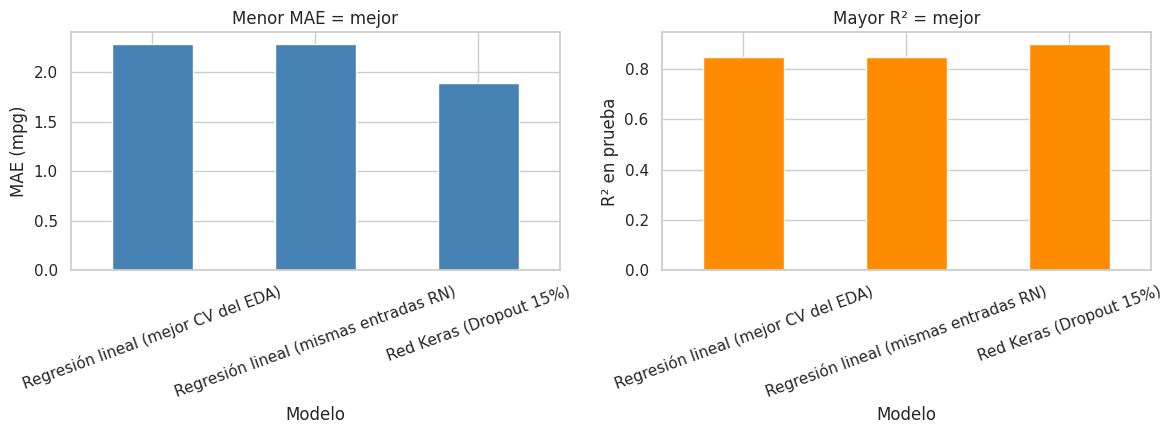

In [ ]:
# Predicciones de ambos modelos lineales y de la red neuronal.
pred_lineal_eda = lineal_eda.predict(prueba[columnas_mejor_lineal]).ravel()
pred_lineal_mismas = lineal_mismas_variables.predict(prueba[variables_red]).ravel()
pred_red = red_final.predict(X_prueba, verbose=0).ravel()

def metricas(y_real, y_estimado):
    return {
        "MAE (mpg)": mean_absolute_error(y_real, y_estimado),
        "RMSE (mpg)": np.sqrt(mean_squared_error(y_real, y_estimado)),
        "R²": r2_score(y_real, y_estimado)
    }

comparacion = pd.DataFrame([
    {"Modelo": "Regresión lineal (mejor CV del EDA)", **metricas(y_prueba, pred_lineal_eda)},
    {"Modelo": "Regresión lineal (mismas entradas RN)", **metricas(y_prueba, pred_lineal_mismas)},
    {"Modelo": f"Red Keras (Dropout {mejor_tasa:.0%})", **metricas(y_prueba, pred_red)}
]).set_index("Modelo")
display(comparacion.round(3))

mae_referencia = float(mean_absolute_error(y_prueba, pred_lineal_eda))
mae_red = float(mean_absolute_error(y_prueba, pred_red))
cambio_porcentual = 100 * (mae_referencia - mae_red) / mae_referencia

if mae_red < mae_referencia:
    print(f"La red MEJORÓ el MAE frente al EDA en {cambio_porcentual:.1f} % en prueba.")
elif mae_red > mae_referencia:
    print(f"La red NO mejoró el MAE: aumentó {abs(cambio_porcentual):.1f} % respecto al EDA.")
else:
    print("Los modelos obtuvieron el mismo MAE en prueba.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparacion["MAE (mpg)"].plot.bar(ax=axes[0], color="steelblue", rot=20)
axes[0].set(title="Menor MAE = mejor", ylabel="MAE (mpg)")
comparacion["R²"].plot.bar(ax=axes[1], color="darkorange", rot=20)
axes[1].set(title="Mayor R² = mejor", ylabel="R² en prueba")
plt.tight_layout()
plt.show()

## 10. Diagnóstico: predicciones y residuos

Un residual es `mpg_real - mpg_predicho`.

- **Real vs. predicho:** los puntos ideales están sobre la diagonal.
- **Residuos vs. valor predicho:** una curva sistemática sugiere que el modelo no captura una relación.
- **Distribución de errores:** un histograma estrecho y centrado en cero suele ser deseable.
- Compararemos los errores de la misma observación con cada modelo.

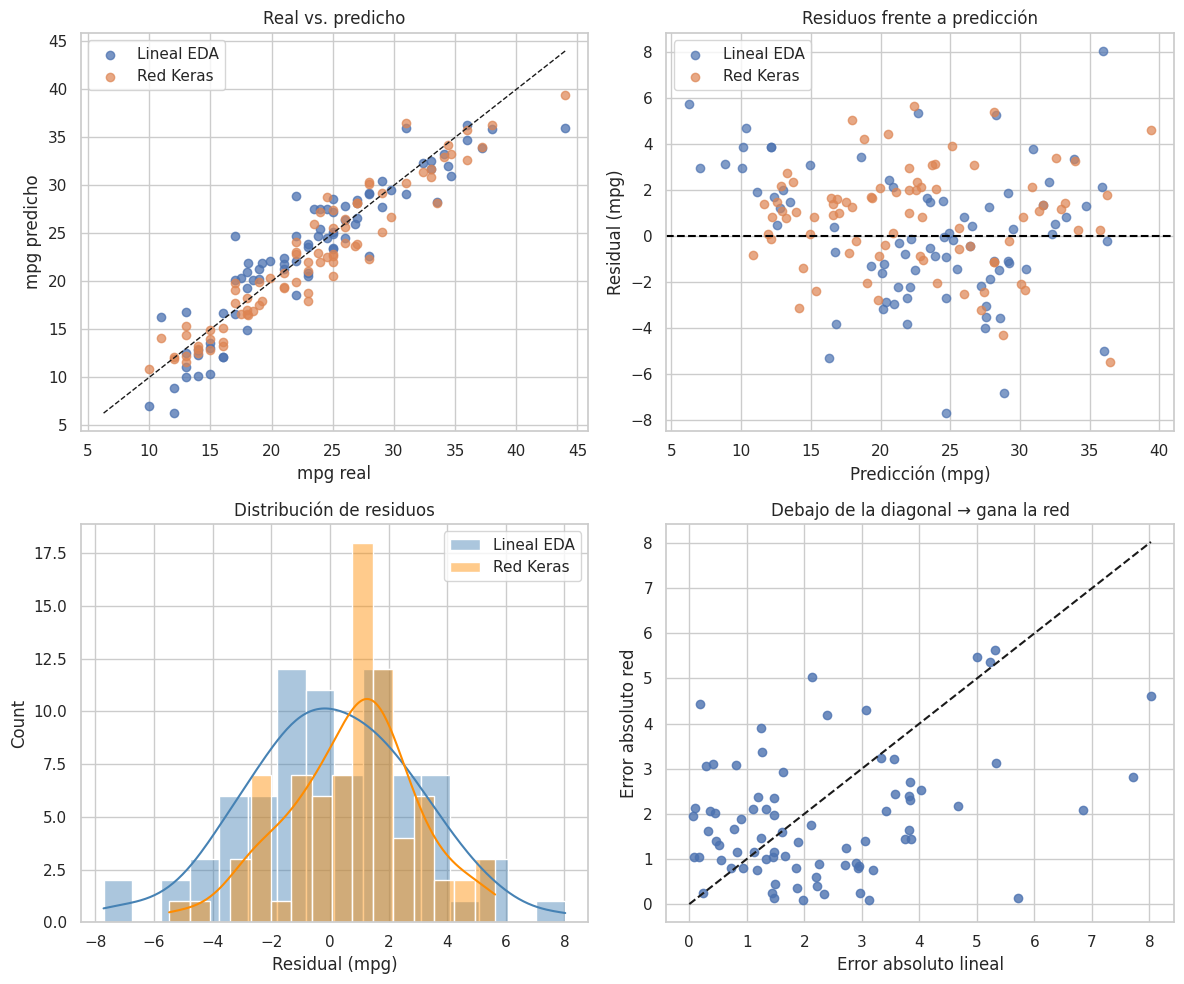

In [ ]:
res_lineal = y_prueba - pred_lineal_eda
res_red = y_prueba - pred_red
lim_inf = float(min(y_prueba.min(), pred_lineal_eda.min(), pred_red.min()))
lim_sup = float(max(y_prueba.max(), pred_lineal_eda.max(), pred_red.max()))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].scatter(y_prueba, pred_lineal_eda, alpha=0.75, label="Lineal EDA")
axes[0, 0].scatter(y_prueba, pred_red, alpha=0.7, label="Red Keras")
axes[0, 0].plot([lim_inf, lim_sup], [lim_inf, lim_sup], "k--", lw=1)
axes[0, 0].set(xlabel="mpg real", ylabel="mpg predicho", title="Real vs. predicho")
axes[0, 0].legend()

axes[0, 1].scatter(pred_lineal_eda, res_lineal, alpha=0.7, label="Lineal EDA")
axes[0, 1].scatter(pred_red, res_red, alpha=0.7, label="Red Keras")
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[0, 1].set(xlabel="Predicción (mpg)", ylabel="Residual (mpg)", title="Residuos frente a predicción")
axes[0, 1].legend()

sns.histplot(x=res_lineal, bins=16, kde=True, ax=axes[1, 0], alpha=0.45, color="steelblue", label="Lineal EDA")
sns.histplot(x=res_red, bins=16, kde=True, ax=axes[1, 0], alpha=0.45, color="darkorange", label="Red Keras")
axes[1, 0].set(xlabel="Residual (mpg)", title="Distribución de residuos")
axes[1, 0].legend()

axes[1, 1].scatter(np.abs(res_lineal), np.abs(res_red), alpha=0.8)
max_err = float(max(np.abs(res_lineal).max(), np.abs(res_red).max()))
axes[1, 1].plot([0, max_err], [0, max_err], "k--")
axes[1, 1].set(xlabel="Error absoluto lineal", ylabel="Error absoluto red", title="Debajo de la diagonal → gana la red")
plt.tight_layout()
plt.show()

### 10.1 ¿En qué automóviles gana o pierde la red?

Cada fila representa un automóvil del conjunto de prueba. La columna `ventaja_red` es **positiva** cuando la red comete menos error absoluto que la regresión lineal, y negativa en caso contrario. Este análisis es solo diagnóstico: no modificaremos el modelo basándonos en él.

In [ ]:
tabla_predicciones = prueba[["car_name", "cylinders", "weight", "model_year", "mpg"]].copy()
tabla_predicciones["pred_lineal"] = pred_lineal_eda
tabla_predicciones["pred_red"] = pred_red
tabla_predicciones["error_lineal"] = np.abs(res_lineal)
tabla_predicciones["error_red"] = np.abs(res_red)
tabla_predicciones["ventaja_red"] = tabla_predicciones["error_lineal"] - tabla_predicciones["error_red"]

print("5 casos donde la red gana más:")
display(tabla_predicciones.nlargest(5, "ventaja_red").round(2))
print("5 casos donde la regresión lineal gana más:")
display(tabla_predicciones.nsmallest(5, "ventaja_red").round(2))

5 casos donde la red gana más:


,car_name,cylinders,weight,model_year,mpg,pred_lineal,pred_red,error_lineal,error_red,ventaja_red
42,dodge monaco (sw),8,4955.0,71,12.0,6.28,12.150000,5.72,0.15,5.58
275,volvo 264gl,6,3140.0,78,17.0,24.72,19.809999,7.72,2.81,4.91
389,ford granada l,6,2835.0,82,22.0,28.85,24.080000,6.85,2.08,4.78
394,vw pickup,4,2130.0,82,44.0,35.97,39.400002,8.03,4.60,3.42
104,ford country,8,4906.0,73,12.0,8.87,11.910000,3.13,0.09,3.04


5 casos donde la regresión lineal gana más:


,car_name,cylinders,weight,model_year,mpg,pred_lineal,pred_red,error_lineal,error_red,ventaja_red
180,saab 99le,4,2671.0,75,25.0,25.18,20.570000,0.18,4.43,-4.25
298,cadillac eldorado,8,3900.0,79,23.0,20.87,17.959999,2.13,5.04,-2.91
318,toyota corona liftback,4,2711.0,80,29.8,29.52,26.730000,0.28,3.07,-2.79
84,toyota corolla 1600 (sw),4,2100.0,72,27.0,26.58,23.879999,0.42,3.12,-2.69
141,audi fox,4,2219.0,74,29.0,27.76,25.100000,1.24,3.90,-2.66


## 11. Opcional: conservar los modelos entrenados

El archivo `.keras` contiene la red entrenada, y `joblib` conserva el transformador **indispensable** para convertir futuros automóviles en entradas normalizadas. También guardamos los dos modelos lineales y la tabla de métricas. Para usar la red posteriormente habrá que reconstruir las mismas siete columnas.

In [ ]:
CARPETA_SALIDA = Path("salida_red_neuronal_mpg")
CARPETA_SALIDA.mkdir(exist_ok=True)
red_final.save(CARPETA_SALIDA / "red_auto_mpg.keras")
dump(pre_final, CARPETA_SALIDA / "preprocesador_red.joblib")
dump(lineal_eda, CARPETA_SALIDA / "lineal_eda.joblib")
dump(lineal_mismas_variables, CARPETA_SALIDA / "lineal_mismas_variables.joblib")
comparacion.to_csv(CARPETA_SALIDA / "comparacion_metricas.csv")
tabla_predicciones.to_csv(CARPETA_SALIDA / "predicciones_test.csv", index=False)
print("Archivos guardados en:", CARPETA_SALIDA.resolve())

Archivos guardados en: /content/drive/MyDrive/EDCO_IntroCienciaDatos/Semana5/Datos/salida_red_neuronal_mpg


## 12. Preguntas para discutir en clase

1. **¿Por qué la red necesita escalado mientras una regresión lineal ordinaria suele funcionar sin él?** Piensa en la optimización por gradiente y la geometría de la función de pérdida.
2. **¿Qué significa que `loss` siga bajando, pero `val_mae` empiece a subir?** Es una pista de sobreajuste; el modelo aprende patrones particulares de entrenamiento.
3. **¿Cuál es la diferencia entre Dropout, L2 y EarlyStopping?** Dropout perturba activaciones durante entrenamiento; L2 penaliza pesos grandes; EarlyStopping controla el número de épocas.
4. **¿Qué indica el RMSE si es claramente mayor que el MAE?** Algunos errores grandes pesan desproporcionadamente en RMSE.
5. **¿Por qué no usar la tasa de Dropout que da el menor error de entrenamiento?** Porque buscamos **generalización**, no memorización.
6. **¿La red es mejor?** Responde exclusivamente con el MAE, RMSE y R² sobre prueba; compara si la mejora (cuando exista) es relevante frente al costo y complejidad.
7. **¿La mejora podría deberse al azar de una sola partición?** Sí. Un trabajo posterior podría usar validación cruzada repetida o varias semillas de entrenamiento **sin reutilizar test para afinar modelos**.

**Idea física-estadística:** el modelo lineal supone efectos aditivos de los predictores (salvo que construyamos interacciones explícitas). Una red con ReLU puede aprender no linealidades e interacciones, pero necesita suficientes datos y regularización para no aprender ruido.

**Referencias técnicas:** [Tutorial oficial Auto MPG de TensorFlow](https://www.tensorflow.org/tutorials/keras/regression) · [Keras EarlyStopping](https://keras.io/api/callbacks/early_stopping/) · [Keras ReduceLROnPlateau](https://keras.io/api/callbacks/reduce_lr_on_plateau/).